# 01 — Data Exploration
**Project:** Cybercrime Cash-Withdrawal Location Forecast

This notebook explores a fully synthetic zone-day dataset. It is for academic experimentation only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/synthetic_atm_data.csv', parse_dates=['date'])
df.head()

,zone_id,date,latitude,longitude,day_of_week,month,is_weekend,atm_count,withdrawal_count,avg_withdrawal_amount,...,unusual_activity_count,cashout_incident_count,withdrawals_sum_7d,unusual_activity_sum_7d,incidents_sum_7d,withdrawals_sum_30d,unusual_activity_sum_30d,incidents_sum_30d,target_incidents_next_7d,target_risk
0,ZONE_01,2025-01-31,31.000914,75.000198,4,1,0,9,121,1953.02,...,3,0,621.0,8.0,4.0,2816.0,42.0,10.0,2,Medium
1,ZONE_01,2025-02-01,31.000914,75.000198,5,2,1,4,113,1508.52,...,2,0,647.0,11.0,3.0,2841.0,45.0,9.0,2,Medium
2,ZONE_01,2025-02-02,31.000914,75.000198,6,2,1,4,104,2560.12,...,1,0,668.0,12.0,2.0,2854.0,47.0,9.0,3,Medium
3,ZONE_01,2025-02-03,31.000914,75.000198,0,2,0,9,104,4288.27,...,1,1,693.0,13.0,2.0,2851.0,45.0,9.0,2,Medium
4,ZONE_01,2025-02-04,31.000914,75.000198,1,2,0,12,77,2664.90,...,0,1,719.0,12.0,3.0,2851.0,44.0,10.0,1,Low


In [2]:
print('Shape:', df.shape)
display(df.info())
display(df.describe(include='all').T)

Shape: (6036, 21)
<class 'pandas.DataFrame'>
RangeIndex: 6036 entries, 0 to 6035
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   zone_id                   6036 non-null   str           
 1   date                      6036 non-null   datetime64[us]
 2   latitude                  6036 non-null   float64       
 3   longitude                 6036 non-null   float64       
 4   day_of_week               6036 non-null   int64         
 5   month                     6036 non-null   int64         
 6   is_weekend                6036 non-null   int64         
 7   atm_count                 6036 non-null   int64         
 8   withdrawal_count          6036 non-null   int64         
 9   avg_withdrawal_amount     6036 non-null   float64       
 10  total_withdrawal_amount   6036 non-null   float64       
 11  unusual_activity_count    6036 non-null   int64         
 12  cashout_incid

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
zone_id,6036,12,ZONE_01,503,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,6036,NaN,NaN,NaN,2025-10-09 00:00:00,2025-01-31 00:00:00,2025-06-05 00:00:00,2025-10-09 00:00:00,2026-02-12 00:00:00,2026-06-17 00:00:00,NaN
latitude,6036.0,NaN,NaN,NaN,31.024575,30.99688,31.002679,31.022572,31.048068,31.052638,0.020548
longitude,6036.0,NaN,NaN,NaN,75.037811,74.999445,75.016869,75.039892,75.058356,75.07485,0.027937
day_of_week,6036.0,NaN,NaN,NaN,3.0,0.0,1.0,3.0,5.0,6.0,2.002153
month,6036.0,NaN,NaN,NaN,5.7833,1.0,3.0,5.0,8.0,12.0,3.252239
is_weekend,6036.0,NaN,NaN,NaN,0.286282,0.0,0.0,0.0,1.0,1.0,0.45206
atm_count,6036.0,NaN,NaN,NaN,7.510934,3.0,5.0,8.0,10.0,12.0,2.862849
withdrawal_count,6036.0,NaN,NaN,NaN,80.18837,37.0,67.0,79.0,92.0,139.0,16.657438
avg_withdrawal_amount,6036.0,NaN,NaN,NaN,2854.332757,500.0,2421.12,2843.32,3280.87,5230.0,642.758002


In [3]:
# Check missing values and duplicate zone-date rows
display(df.isna().sum().sort_values(ascending=False))
print('Duplicate zone-date rows:', df.duplicated(['zone_id', 'date']).sum())

zone_id                     0
date                        0
latitude                    0
longitude                   0
day_of_week                 0
month                       0
is_weekend                  0
atm_count                   0
withdrawal_count            0
avg_withdrawal_amount       0
total_withdrawal_amount     0
unusual_activity_count      0
cashout_incident_count      0
withdrawals_sum_7d          0
unusual_activity_sum_7d     0
incidents_sum_7d            0
withdrawals_sum_30d         0
unusual_activity_sum_30d    0
incidents_sum_30d           0
target_incidents_next_7d    0
target_risk                 0
dtype: int64

Duplicate zone-date rows: 0


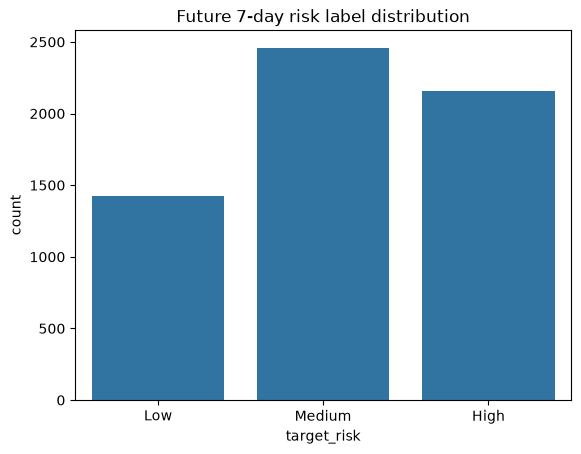

In [4]:
# Target distribution
ax = sns.countplot(data=df, x='target_risk', order=['Low', 'Medium', 'High'])
ax.set_title('Future 7-day risk label distribution')
plt.show()

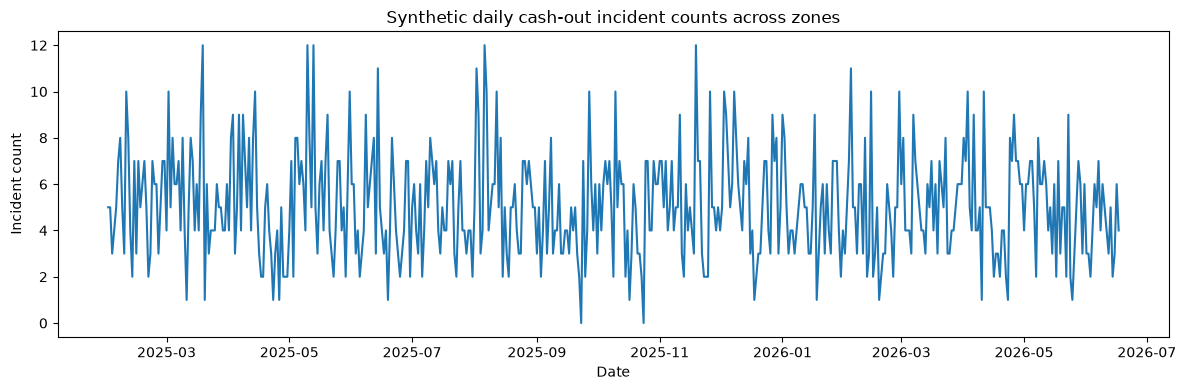

In [5]:
# Incident counts over time (all zones aggregated)
daily = df.groupby('date', as_index=False)['cashout_incident_count'].sum()
plt.figure(figsize=(12, 4))
plt.plot(daily['date'], daily['cashout_incident_count'])
plt.title('Synthetic daily cash-out incident counts across zones')
plt.xlabel('Date'); plt.ylabel('Incident count'); plt.tight_layout(); plt.show()

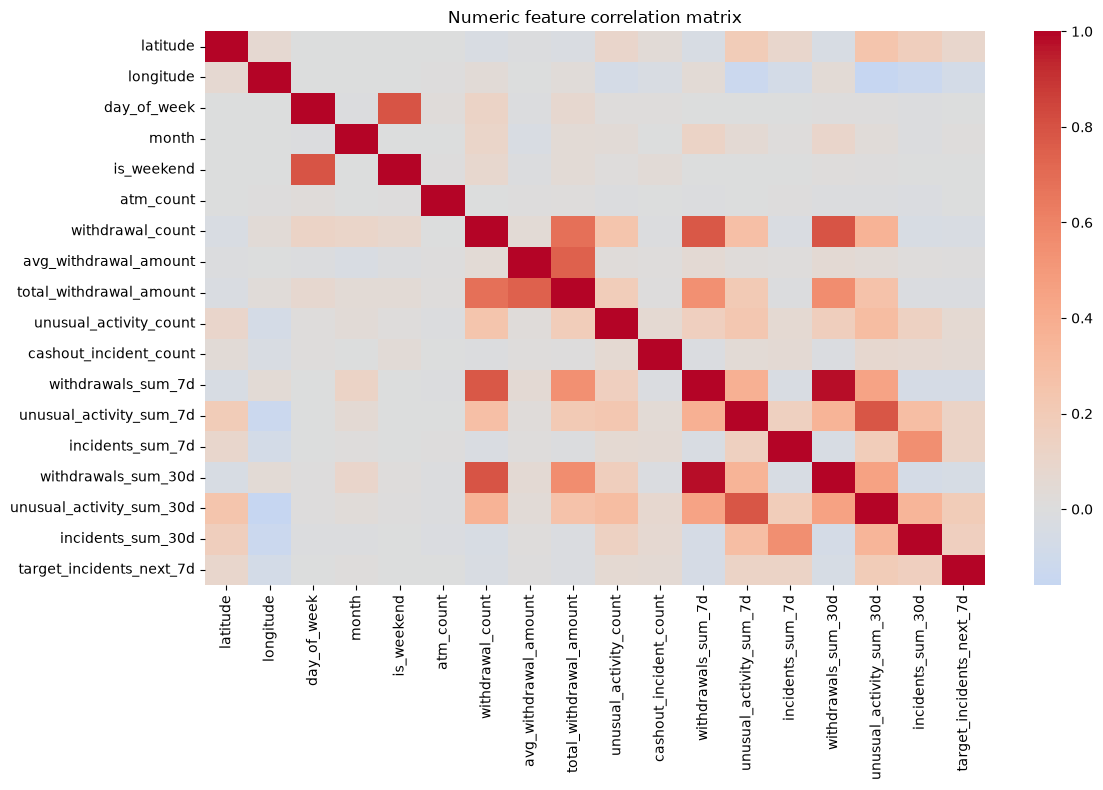

In [6]:
# Correlations among numeric columns (exploratory only)
numeric = df.select_dtypes(include='number')
plt.figure(figsize=(12, 8))
sns.heatmap(numeric.corr(), cmap='coolwarm', center=0)
plt.title('Numeric feature correlation matrix')
plt.tight_layout(); plt.show()

## Phase 1 checks
- Confirm each row is one zone-day.
- Confirm predictors use only information available before the forecast date.
- Keep `target_incidents_next_7d` and `target_risk` out of model input features.
- Use chronological train/test splits in later phases.
- Because the dataset is synthetic, do not report its results as real-world performance.